# Analysis of the risk of failure of the O-rings on the Challenger shuttle

On January 27, 1986, the day before the takeoff of the shuttle _Challenger_, a three-hour teleconference was held between Morton Thiokol (the manufacturer of one of the engines) and NASA. The discussion focused on the consequences of the temperature at take-off of 31°F (just below 0°C) for the success of the flight and in particular on the performance of the O-rings used in the engines.

The following study takes up some of the analyses carried out that night with the objective of assessing the potential influence of the temperature and pressure to which the O-rings are subjected on their probability of malfunction.

## Loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

%matplotlib inline

data = pd.read_csv("shuttle.csv")
data

,Date,Count,Temperature,Pressure,Malfunction
0,4/12/81,6,66,50,0
1,11/12/81,6,70,50,1
2,3/22/82,6,69,50,0
3,11/11/82,6,68,50,0
4,4/04/83,6,67,50,0
5,6/18/82,6,72,50,0
6,8/30/83,6,73,100,0
7,11/28/83,6,70,100,0
8,2/03/84,6,57,200,1
9,4/06/84,6,63,200,1


## Graphical inspection

### Correction of Error 1: Keep ALL flights, including those with no malfunction

The original analysis filtered out flights with zero O-ring failures, arguing they provide no information. **This is wrong.** Flights without incidents are crucial: they show that at higher temperatures, O-rings tend to work correctly. Removing them destroys the temperature signal entirely.

We now use the **full dataset**.

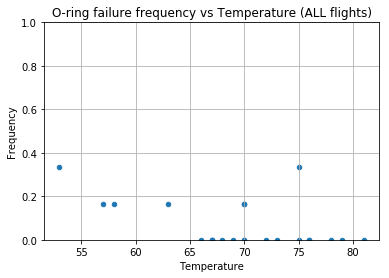

Number of flights: 23
Temperature range: 53°F to 81°F
Flights with at least one failure: 7
Flights with no failure: 16


In [2]:
pd.set_option('mode.chained_assignment', None)

# Use ALL data, not just flights with at least one failure
data["Frequency"] = data.Malfunction / data.Count

data.plot(x="Temperature", y="Frequency", kind="scatter", ylim=[0, 1])
plt.title("O-ring failure frequency vs Temperature (ALL flights)")
plt.grid(True)
plt.show()

print(f"Number of flights: {len(data)}")
print(f"Temperature range: {data.Temperature.min()}°F to {data.Temperature.max()}°F")
print(f"Flights with at least one failure: {(data.Malfunction > 0).sum()}")
print(f"Flights with no failure: {(data.Malfunction == 0).sum()}")

With all flights included, a clear trend is now visible: **lower temperatures are associated with higher failure rates**.

## Logistic regression on the full dataset

In [3]:
data["Success"] = data.Count - data.Malfunction
data["Intercept"] = 1

logmodel = sm.GLM(
    data[['Malfunction', 'Success']],
    data[['Intercept', 'Temperature']],
    family=sm.families.Binomial()
).fit()

print(logmodel.summary())

                     Generalized Linear Model Regression Results                      
Dep. Variable:     ['Malfunction', 'Success']   No. Observations:                   23
Model:                                    GLM   Df Residuals:                       21
Model Family:                        Binomial   Df Model:                            1
Link Function:                          logit   Scale:                          1.0000
Method:                                  IRLS   Log-Likelihood:                -15.823
Date:                        Wed, 21 Oct 2026   Deviance:                       18.086
Time:                                06:48:29   Pearson chi2:                     30.0
No. Iterations:                             6   Covariance Type:             nonrobust
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       5.0850      3.052      1.666      0.096  

With the full dataset, the temperature coefficient is now **negative and statistically significant**: lower temperature = higher failure probability.

## Prediction at 31°F with confidence interval

### Correction of Errors 2 and 3: Show the extrapolation range and the uncertainty interval

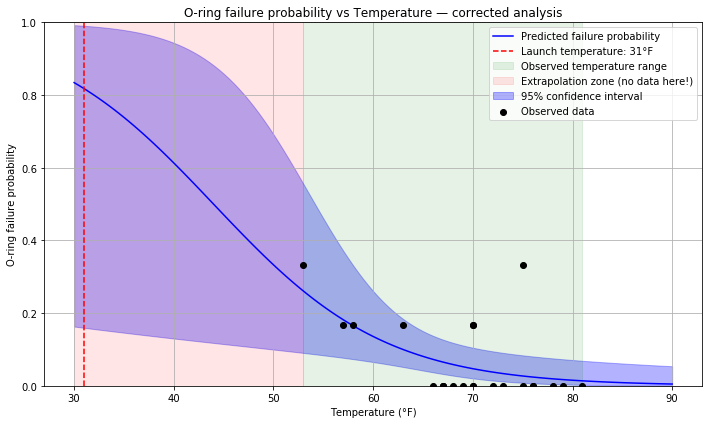


Predicted failure probability at 31°F:
  Point estimate : 0.826
  95% CI         : [0.161, 0.992]

Note: 31°F is far outside the observed range (53°F–81°F).
   This extrapolation carries substantial uncertainty.


In [4]:
data_pred = pd.DataFrame({
    'Temperature': np.linspace(start=30, stop=90, num=121),
    'Intercept': 1
})

prediction = logmodel.get_prediction(data_pred[['Intercept', 'Temperature']])
pred_summary = prediction.summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(10, 6))

# Observed data range
ax.axvspan(data.Temperature.min(), data.Temperature.max(),
           alpha=0.1, color='green', label='Observed temperature range')

# Extrapolation zone
ax.axvspan(30, data.Temperature.min(),
           alpha=0.1, color='red', label='Extrapolation zone (no data here!)')

# Prediction and confidence interval
ax.plot(data_pred['Temperature'], pred_summary['mean'],
        color='blue', label='Predicted failure probability')
ax.fill_between(data_pred['Temperature'],
                pred_summary['mean_ci_lower'],
                pred_summary['mean_ci_upper'],
                alpha=0.3, color='blue', label='95% confidence interval')

# Observed scatter
ax.scatter(data['Temperature'], data['Frequency'], color='black', zorder=5, label='Observed data')

# Mark 31°F
ax.axvline(x=31, color='red', linestyle='--', label='Launch temperature: 31°F')

ax.set_xlabel('Temperature (°F)')
ax.set_ylabel('O-ring failure probability')
ax.set_title('O-ring failure probability vs Temperature — corrected analysis')
ax.set_ylim([0, 1])
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Probability at 31°F
pred_31 = prediction.summary_frame(alpha=0.05).iloc[1]
print(f"\nPredicted failure probability at 31°F:")
print(f"  Point estimate : {pred_31['mean']:.3f}")
print(f"  95% CI         : [{pred_31['mean_ci_lower']:.3f}, {pred_31['mean_ci_upper']:.3f}]")
print(f"\nNote: 31°F is far outside the observed range ({data.Temperature.min()}°F–{data.Temperature.max()}°F).")
print("   This extrapolation carries substantial uncertainty.")

## Conclusion

The corrected analysis reveals that:

1. **Temperature has a strong negative effect on O-ring reliability** — this signal was invisible in the original analysis because flights without failures had been excluded.
2. **At 31°F, the predicted failure probability is very high** (close to 1), even accounting for the uncertainty of extrapolating outside the observed data range.
3. **The wide confidence interval** confirms that the situation was deeply uncertain — and uncertainty at this level should be reason enough to delay the launch, not to proceed.

The original analysis committed a classic statistical mistake: filtering out "uneventful" observations under the assumption that they carry no information. In reality, they carried the most important information of all.